In [1]:
# Team guide: Section 2.5 — run this cell first.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Our area (from pilot_area.md) - do not change
W, S, E, N = 30.70, 31.05, 30.91, 31.30       # West, South, East, North
LAT_C, LON_C = 31.175, 30.805                 # center point
START_YEAR, END_YEAR = 2016, 2024             # full years for final tables

assert 31 <= S < N < 32, "Latitude is wrong. Did you swap lat and lon?"
assert 30 <= W < E < 31, "Longitude is wrong. Did you swap lat and lon?"
print("Area OK")

Area OK


# NASA POWER — Exploratory Data Analysis (EDA)
**Project:** Neural Nile / Plan B Farm AI — NASA Space Apps Field Shift  
**File:** `notebooks/01_nasa_power.ipynb`  
**Pilot point:** 31.175°N, 30.805°E (Kafr El-Sheikh, Egypt)  
**Daily download:** **2015-01-01 to 2024-12-31** (3,653 calendar days)  
**Final monthly tables:** **2016-01 to 2024-12** (**108 months**)  

This notebook follows the **seven EDA sections** in `data_workflow.md` (section 7), with the code and output contract from **section 6.2**. It replaces the previous 2016–2025, two-variable notebook.

**Colab:** Open the notebook and choose **Runtime → Run all**. Standard Python libraries listed here are usually available in Colab; no separate installation cell is required. Running the notebook downloads fresh data from the NASA POWER API, so an Internet connection is needed in Colab.

**Storage:** When run from a cloned repository's `notebooks` directory, outputs go to the repository's `data/` directory. When uploaded directly to Colab (`/content`), outputs go to `/content/data/`. Download these files before a temporary Colab session expires.

**Never push** `data/raw/power_raw.json` to GitHub. Push your notebook and the two small CSV files from `data/processed/` only.

## 1. What is this dataset?

**NASA POWER** (Prediction Of Worldwide Energy Resources) provides daily *gridded climate estimates*. The **Daily Point API** returns values near our pilot-area center: this is **not** weather measured on a particular farm and **not** a 1-km grid.

| NASA parameter | Team output column | Physical quantity | Expected unit |
|---|---|---|---|
| `T2M` | `t_mean_c` | Daily mean air temperature (2 m) | °C |
| `T2M_MAX` | `t_max_c` | Daily maximum air temperature (2 m) | °C |
| `T2M_MIN` | `t_min_c` | Daily minimum air temperature (2 m) | °C |
| `RH2M` | `rh_pct` | Relative humidity (2 m) | % |
| `WS2M` | `wind_ms` | Wind speed (2 m) | m/s |
| `ALLSKY_SFC_SW_DWN` | `solar_mj_m2_day` | All-sky surface shortwave radiation | MJ/m²/day |
| `PRECTOTCORR` | `power_rain_mm` | Corrected daily precipitation estimate | mm/day |

**Why these matter:** temperature (including daily max/min), relative humidity, wind, sunshine and precipitation can help characterize agricultural conditions and model crop rotation. Crop recommendations still require soil, water access, crop calendars and other inputs.

**Source:** https://power.larc.nasa.gov/ — **API:** https://power.larc.nasa.gov/api/temporal/daily/point

## 2. Download a small sample (one point)

Download **one NASA POWER point**; do not download a regional raster. Keep the original JSON in `data/raw/` for traceability. Print the returned units before processing—especially wind and solar radiation.

**Date convention:** Daily source includes 2015–2024; the final monthly output excludes 2015 and contains 2016–2024 only, as agreed by the team.

In [2]:
import requests
import json
from pathlib import Path
from datetime import datetime, timezone

# Works in Colab /content, repository root, or repository/notebooks.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
RAW_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

PARAMETERS = [
    "T2M", "T2M_MAX", "T2M_MIN", "RH2M", "WS2M",
    "ALLSKY_SFC_SW_DWN", "PRECTOTCORR"
]
URL = "https://power.larc.nasa.gov/api/temporal/daily/point"
params = {
    "parameters": ",".join(PARAMETERS),
    "community": "AG",
    "latitude": LAT_C,
    "longitude": LON_C,
    "start": "20150101",
    "end": "20241231",
    "format": "JSON",
    "units": "METRIC",
}
response = requests.get(URL, params=params, timeout=300)
response.raise_for_status()
data = response.json()
assert "properties" in data and "parameter" in data["properties"], "Unexpected NASA POWER response"

RAW_PATH = RAW_DIR / "power_raw.json"
with RAW_PATH.open("w", encoding="utf-8") as f:
    json.dump(data, f)

print("HTTP status:", response.status_code)
print("API request:", response.url)
print("Downloaded (UTC):", datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M"))
print("Raw JSON:", RAW_PATH, "| KB:", round(RAW_PATH.stat().st_size / 1024, 1))
print("\nUnit metadata returned by NASA POWER:")
for key in PARAMETERS:
    print(f"  {key}: {data.get('parameters', {}).get(key, 'Not supplied')}")

HTTP status: 200
API request: https://power.larc.nasa.gov/api/temporal/daily/point?parameters=T2M%2CT2M_MAX%2CT2M_MIN%2CRH2M%2CWS2M%2CALLSKY_SFC_SW_DWN%2CPRECTOTCORR&community=AG&latitude=31.175&longitude=30.805&start=20150101&end=20241231&format=JSON&units=METRIC
Downloaded (UTC): 2026-11-13 19:13
Raw JSON: /Users/fatmahadad/Documents/data/raw/power_raw.json | KB: 462.8

Unit metadata returned by NASA POWER:
  T2M: {'units': 'C', 'longname': 'Temperature at 2 Meters'}
  T2M_MAX: {'units': 'C', 'longname': 'Temperature at 2 Meters Maximum'}
  T2M_MIN: {'units': 'C', 'longname': 'Temperature at 2 Meters Minimum'}
  RH2M: {'units': '%', 'longname': 'Relative Humidity at 2 Meters'}
  WS2M: {'units': 'm/s', 'longname': 'Wind Speed at 2 Meters'}
  ALLSKY_SFC_SW_DWN: {'units': 'MJ/m^2/day', 'longname': 'All Sky Surface Shortwave Downward Irradiance'}
  PRECTOTCORR: {'units': 'mm/day', 'longname': 'Precipitation Corrected'}


In [4]:
# Parse, sort, retain NaN for missing (never substitute 0).
rename = {
    "T2M": "t_mean_c",
    "T2M_MAX": "t_max_c",
    "T2M_MIN": "t_min_c",
    "RH2M": "rh_pct",
    "WS2M": "wind_ms",
    "ALLSKY_SFC_SW_DWN": "solar_mj_m2_day",
    "PRECTOTCORR": "power_rain_mm",
}

raw_table = pd.DataFrame(data["properties"]["parameter"])
missing_parameters = set(PARAMETERS) - set(raw_table.columns)
assert not missing_parameters, f"Missing requested parameters: {missing_parameters}"

raw_table.index = pd.to_datetime(raw_table.index, format="%Y%m%d")
raw_table.index.name = "date"
raw_table = raw_table.sort_index()
df = raw_table[PARAMETERS].apply(pd.to_numeric, errors="coerce")
# NASA POWER missing code. Missing values remain empty in exported CSVs.
df = df.replace([-999.0, -9999.0, -9999.9], np.nan)
df = df.rename(columns=rename)

EXPECTED_DATES = pd.date_range("2015-01-01", "2024-12-31", freq="D", name="date")
print("Shape (days, variables):", df.shape)
print("First / last day:", df.index.min().date(), df.index.max().date())
print("Variables:", df.columns.tolist())
display(df.head())

Shape (days, variables): (3653, 7)
First / last day: 2015-01-01 2024-12-31
Variables: ['t_mean_c', 't_max_c', 't_min_c', 'rh_pct', 'wind_ms', 'solar_mj_m2_day', 'power_rain_mm']


,t_mean_c,t_max_c,t_min_c,rh_pct,wind_ms,solar_mj_m2_day,power_rain_mm
date,,,,,,,
2015-01-01,11.87,16.86,8.45,51.75,4.21,8.48,0.00
2015-01-02,12.92,19.99,8.51,64.24,2.59,10.14,0.00
2015-01-03,12.77,18.66,7.71,57.42,3.56,10.35,0.79
2015-01-04,13.02,18.85,9.12,65.37,2.99,11.06,0.11
2015-01-05,12.88,18.29,8.06,61.19,5.87,9.52,0.06


## 3. Look at the data — shape, dates, columns

Expected: **3,653 dates × 7 variables** covering the 10 full calendar years **2015–2024**. We use the source's daily timestamps and keep rainfall as a daily total (mm/day), *not* a monthly average.

In [5]:
assert not df.index.has_duplicates, "Duplicate dates: inspect source before proceeding"
missing_dates = EXPECTED_DATES.difference(df.index)
extra_dates = df.index.difference(EXPECTED_DATES)
assert len(missing_dates) == 0, f"Source is missing {len(missing_dates)} calendar dates"
assert len(extra_dates) == 0, f"Unexpected dates: {extra_dates[:5].tolist()}"
assert len(df) == 3653, f"Expected 3,653 daily rows; got {len(df)}"
assert len(df.columns) == 7, "Expected seven team variables"

print("Dates:", df.index.min().date(), "through", df.index.max().date())
print("Rows:", len(df), "| Variables:", len(df.columns))
print("Dtypes:")
print(df.dtypes.to_string())
print("\nDescriptive statistics:")
display(df.describe().round(2))
print("\nLatest rows:")
display(df.tail())

Dates: 2015-01-01 through 2024-12-31
Rows: 3653 | Variables: 7
Dtypes:
t_mean_c           float64
t_max_c            float64
t_min_c            float64
rh_pct             float64
wind_ms            float64
solar_mj_m2_day    float64
power_rain_mm      float64

Descriptive statistics:


,t_mean_c,t_max_c,t_min_c,rh_pct,wind_ms,solar_mj_m2_day,power_rain_mm
count,3653.00,3653.00,3653.00,3653.00,3653.00,3653.00,3653.00
mean,22.18,29.67,16.43,59.93,2.93,19.57,0.50
std,6.28,7.46,5.53,9.53,0.89,6.88,2.88
min,8.58,11.46,2.76,23.37,0.90,2.07,0.00
25%,16.44,23.03,11.41,54.02,2.34,13.22,0.00
50%,22.65,30.29,16.80,58.90,2.87,20.30,0.00
75%,28.29,36.27,21.72,66.22,3.43,25.98,0.02
max,34.64,46.54,27.28,90.63,7.48,30.58,90.97



Latest rows:


,t_mean_c,t_max_c,t_min_c,rh_pct,wind_ms,solar_mj_m2_day,power_rain_mm
date,,,,,,,
2024-12-27,11.81,16.79,6.87,59.58,4.93,6.36,0.34
2024-12-28,13.08,19.59,6.64,69.85,3.32,7.67,1.11
2024-12-29,13.88,18.88,9.30,73.14,3.36,8.65,0.99
2024-12-30,13.83,18.81,10.79,67.64,3.08,9.09,0.34
2024-12-31,14.29,19.18,11.02,67.97,3.02,10.52,0.16


## 4. Missing values — how many and where?

Look for both **missing dates** and **missing measurements** (these are different). Missing numerical values stay `NaN` and are exported as blank CSV entries. Do not use 0 as a replacement for missing rain.

Missing dates: 0
Duplicate dates: 0
Missing measurements per variable:


,missing_days
t_mean_c,0
t_max_c,0
t_min_c,0
rh_pct,0
wind_ms,0
solar_mj_m2_day,0
power_rain_mm,0


Missing measurements by year:


,t_mean_c,t_max_c,t_min_c,rh_pct,wind_ms,solar_mj_m2_day,power_rain_mm
year,,,,,,,
2015,0,0,0,0,0,0,0
2016,0,0,0,0,0,0,0
2017,0,0,0,0,0,0,0
2018,0,0,0,0,0,0,0
2019,0,0,0,0,0,0,0
2020,0,0,0,0,0,0,0
2021,0,0,0,0,0,0,0
2022,0,0,0,0,0,0,0
2023,0,0,0,0,0,0,0


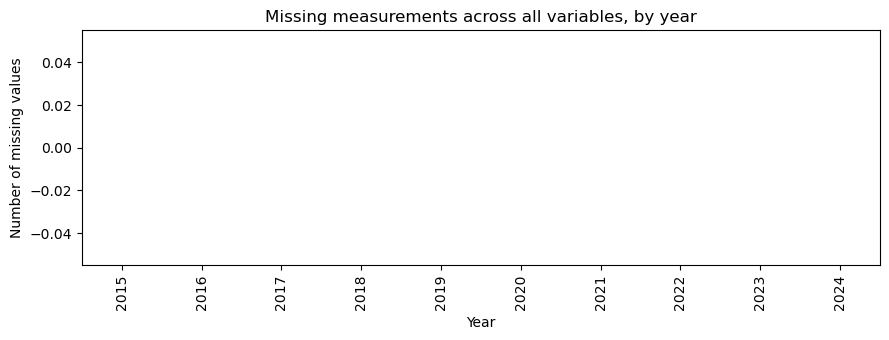

In [6]:
missing_by_variable = df.isna().sum().rename("missing_days")
missing_by_year = df.isna().groupby(df.index.year).sum()
missing_by_year.index.name = "year"

print("Missing dates:", len(missing_dates))
print("Duplicate dates:", int(df.index.duplicated().sum()))
print("Missing measurements per variable:")
display(missing_by_variable.to_frame())
print("Missing measurements by year:")
display(missing_by_year)

ax = missing_by_year.sum(axis=1).plot(kind="bar", figsize=(9, 3.5))
ax.set_title("Missing measurements across all variables, by year")
ax.set_xlabel("Year")
ax.set_ylabel("Number of missing values")
plt.tight_layout()
plt.show()

## 5. Simple plots — daily, annual, seasonal

Use **complete years 2016–2024 only** for comparisons across datasets:

- Temperature, humidity, wind and solar energy → **monthly/annual mean**.
- Precipitation → **monthly/annual sum**, never mean.
- An average over January–December (monthly climatology) shows the normal seasonal pattern.
- Plot daily maximum temperature to support later heat-risk analysis.

Annual mean temperature and total rainfall (2016–2024):


,t_mean_c,power_rain_mm
year,,
2016,22.18,171.87
2017,21.52,185.95
2018,22.61,114.25
2019,21.97,100.61
2020,21.82,312.72
2021,22.30,344.72
2022,21.72,199.88
2023,22.91,151.57
2024,22.91,64.59


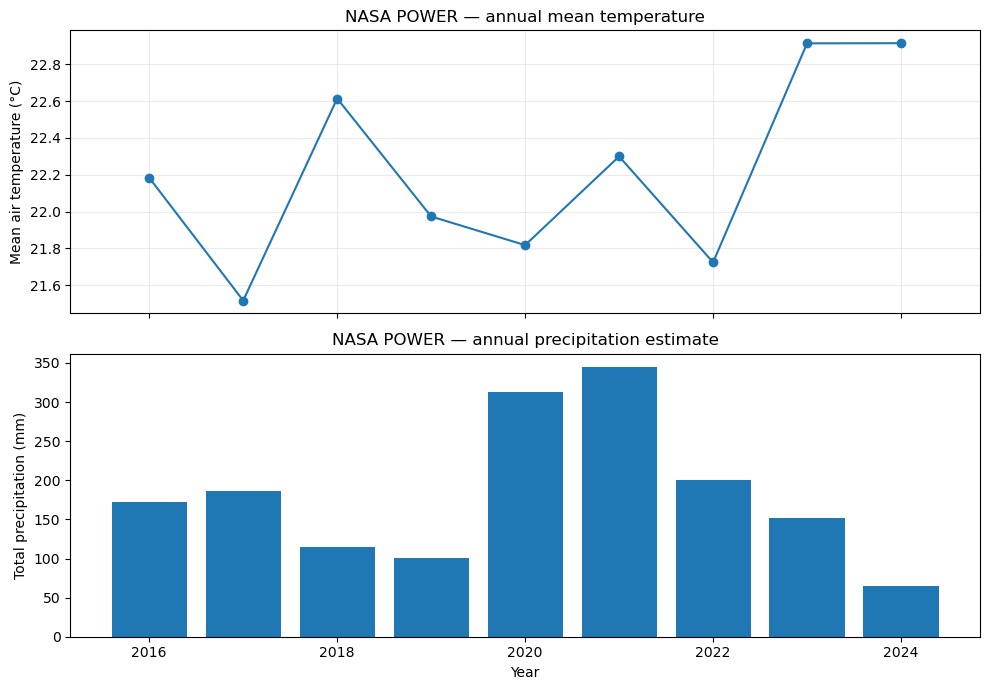

In [7]:
# Final analysis years (exclude 2015 from yearly/monthly comparative plots).
analysis = df.loc["2016-01-01":"2024-12-31"].copy()

annual = analysis.resample("YS").mean(numeric_only=True)
annual["power_rain_mm"] = analysis["power_rain_mm"].resample("YS").sum(min_count=1)
annual.index = annual.index.year
annual.index.name = "year"

print("Annual mean temperature and total rainfall (2016–2024):")
display(annual[["t_mean_c", "power_rain_mm"]].round(2))

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
axes[0].plot(annual.index, annual["t_mean_c"], marker="o")
axes[0].set_ylabel("Mean air temperature (°C)")
axes[0].set_title("NASA POWER — annual mean temperature")
axes[0].grid(alpha=0.25)
axes[1].bar(annual.index, annual["power_rain_mm"])
axes[1].set_ylabel("Total precipitation (mm)")
axes[1].set_xlabel("Year")
axes[1].set_title("NASA POWER — annual precipitation estimate")
plt.tight_layout()
plt.show()

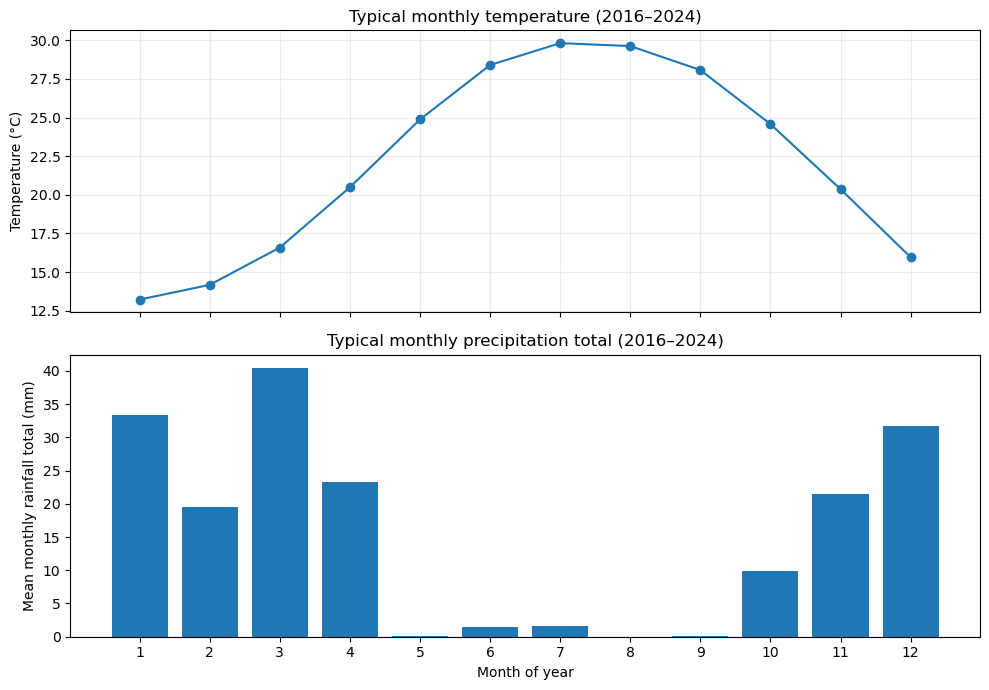

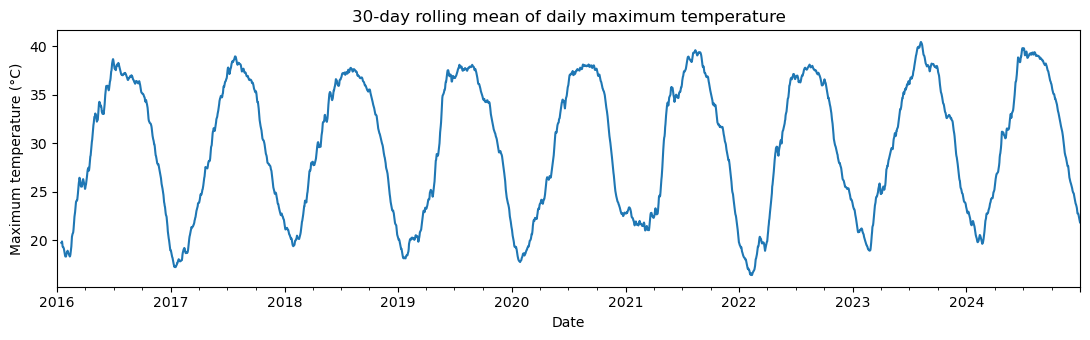

In [8]:
monthly_eda = analysis.resample("MS").mean(numeric_only=True)
monthly_eda["power_rain_mm"] = analysis["power_rain_mm"].resample("MS").sum(min_count=1)
seasonal = monthly_eda.groupby(monthly_eda.index.month).mean(numeric_only=True)
seasonal.index.name = "month"
assert len(monthly_eda) == 108

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
axes[0].plot(seasonal.index, seasonal["t_mean_c"], marker="o")
axes[0].set_title("Typical monthly temperature (2016–2024)")
axes[0].set_ylabel("Temperature (°C)")
axes[0].grid(alpha=0.25)
axes[1].bar(seasonal.index, seasonal["power_rain_mm"])
axes[1].set_title("Typical monthly precipitation total (2016–2024)")
axes[1].set_ylabel("Mean monthly rainfall total (mm)")
axes[1].set_xlabel("Month of year")
axes[1].set_xticks(range(1, 13))
plt.tight_layout()
plt.show()

# Daily maximum temperature: light rolling mean to make long series legible.
ax = analysis["t_max_c"].rolling(30, min_periods=15).mean().plot(figsize=(11, 3.5))
ax.set_title("30-day rolling mean of daily maximum temperature")
ax.set_xlabel("Date")
ax.set_ylabel("Maximum temperature (°C)")
plt.tight_layout()
plt.show()

## 6. Problems found — quality control, rainfall flag and data cleaning

**Previously identified rainfall discrepancy (needs review):** NASA POWER reported **90.97 mm** on **2021-03-19**, while the earlier ERA5 point comparison returned **0.1 mm**. A GPM Final Run plot over a *nearby small area* also appeared much lower, but an exact GPM value was **not** downloaded. The sources differ in resolution, spatial aggregation and possibly time conventions, so this is **a quality-control flag—not proof that the POWER value is wrong**.

**Rules applied here:**
1. Retain raw JSON and never overwrite it.
2. Map fill codes to `NaN`; check duplicate/missing dates.
3. Replace physically invalid negative precipitation, negative wind/solar, and humidity outside 0–100% with `NaN` **only if encountered**; print counts.
4. Flag very large precipitation (`>50 mm/day`) for investigation; this is a **screening threshold, not a statistical definition of error**. **Do not delete flagged rainfall** automatically.
5. Keep the *flag in the notebook's QA report*, not as a surprise extra column in the team's required 7-variable CSV.
6. Rainfall missing values are not zero. Sum with `min_count=1` to leave fully missing periods empty.

**Sensitivity analysis** below estimates how annual 2021 rain total would differ **if** the 2021-03-19 value were excluded for analysis; the actual export **preserves** the observation.

In [9]:
# Use a separate cleaned copy; raw JSON stays unchanged.
clean = df.copy()

quality_counts = {}
invalid_tests = {
    "negative_rain": clean["power_rain_mm"] < 0,
    "negative_wind": clean["wind_ms"] < 0,
    "negative_solar": clean["solar_mj_m2_day"] < 0,
    "humidity_outside_0_100": clean["rh_pct"].notna() & ~clean["rh_pct"].between(0, 100),
}
invalid_columns = {
    "negative_rain": "power_rain_mm",
    "negative_wind": "wind_ms",
    "negative_solar": "solar_mj_m2_day",
    "humidity_outside_0_100": "rh_pct",
}
for issue, mask in invalid_tests.items():
    quality_counts[issue] = int(mask.sum())
    clean.loc[mask, invalid_columns[issue]] = np.nan

# Temperature consistency: flag only, do not change without investigation.
temp_inconsistent = (
    (clean["t_min_c"] > clean["t_max_c"]) |
    (clean["t_mean_c"] < clean["t_min_c"]) |
    (clean["t_mean_c"] > clean["t_max_c"])
)
quality_counts["temperature_inconsistent"] = int(temp_inconsistent.sum())

# Keep all plausible-but-high rain values in the exported data.
rainfall_needs_review = clean["power_rain_mm"] > 50
review_days = clean.loc[rainfall_needs_review, ["power_rain_mm"]].copy()
review_days["rainfall_needs_review"] = True

print("Invalid-value counts (replaced with NaN):")
print({k:v for k,v in quality_counts.items() if k != "temperature_inconsistent"})
print("Temperature consistency warnings (not auto-edited):", quality_counts["temperature_inconsistent"])
print("Rainfall values flagged for review (>50 mm/day):", int(rainfall_needs_review.sum()))
display(review_days)

check_day = pd.Timestamp("2021-03-19")
if check_day in clean.index:
    print("NASA POWER rainfall on 2021-03-19 (mm):", clean.loc[check_day, "power_rain_mm"])

Invalid-value counts (replaced with NaN):
{'negative_rain': 0, 'negative_wind': 0, 'negative_solar': 0, 'humidity_outside_0_100': 0}
Temperature consistency warnings (not auto-edited): 0
Rainfall values flagged for review (>50 mm/day): 1


,power_rain_mm,rainfall_needs_review
date,,
2021-03-19,90.97,True


NASA POWER rainfall on 2021-03-19 (mm): 90.97


In [10]:
# Sensitivity illustration only. The exported CSV keeps the original high value.
base_2021 = clean.loc["2021", "power_rain_mm"].sum(min_count=1)
without_march19 = clean.loc["2021", "power_rain_mm"].copy()
without_march19.loc[pd.Timestamp("2021-03-19")] = np.nan
sensitivity_2021 = without_march19.sum(min_count=1)

print("2021 precipitation total WITH 2021-03-19 (mm):", round(base_2021, 2))
print("2021 hypothetical total WITHOUT that day (mm):", round(sensitivity_2021, 2))
print("Difference (mm):", round(base_2021 - sensitivity_2021, 2))
print("Only a sensitivity test: we have NOT removed the observation from 'clean'.")

2021 precipitation total WITH 2021-03-19 (mm): 344.72
2021 hypothetical total WITHOUT that day (mm): 253.75
Difference (mm): 90.97
Only a sensitivity test: we have NOT removed the observation from 'clean'.


In [11]:
# Output contract from team guide §6.2:
# power_daily.csv: 3653 rows, 2015–2024, with 'date' + 7 named columns.
# power_monthly.csv: 108 rows, 2016–2024, with year, month + 7 named columns.

daily_out = clean.reset_index()
daily_out["date"] = daily_out["date"].dt.strftime("%Y-%m-%d")

monthly = clean.resample("MS").mean(numeric_only=True)
monthly["power_rain_mm"] = clean["power_rain_mm"].resample("MS").sum(min_count=1)
monthly = monthly.loc[f"{START_YEAR}-01-01": f"{END_YEAR}-12-01"].copy()
monthly.insert(0, "year", monthly.index.year.astype(int))
monthly.insert(1, "month", monthly.index.month.astype(int))
monthly_out = monthly.reset_index(drop=True)

expected_names = [
    "t_mean_c", "t_max_c", "t_min_c", "rh_pct", "wind_ms",
    "solar_mj_m2_day", "power_rain_mm"
]
assert list(daily_out.columns) == ["date"] + expected_names, "Daily CSV schema mismatch"
assert list(monthly_out.columns) == ["year", "month"] + expected_names, "Monthly CSV schema mismatch"
assert len(daily_out) == 3653 and len(monthly_out) == 108, "Unexpected output row count"
assert not daily_out.duplicated(["date"]).any()
assert not monthly_out.duplicated(["year", "month"]).any()
assert monthly_out["year"].between(2016, 2024).all()
assert monthly_out["month"].between(1, 12).all()

DAILY_PATH = PROCESSED_DIR / "power_daily.csv"
MONTHLY_PATH = PROCESSED_DIR / "power_monthly.csv"
daily_out.to_csv(DAILY_PATH, index=False, na_rep="")
monthly_out.to_csv(MONTHLY_PATH, index=False, na_rep="")

print("Saved:", DAILY_PATH, "| rows:", len(daily_out), "| KB:", round(DAILY_PATH.stat().st_size / 1024, 1))
print("Saved:", MONTHLY_PATH, "| rows:", len(monthly_out), "| KB:", round(MONTHLY_PATH.stat().st_size / 1024, 1))
print("\nFirst five monthly rows:")
display(monthly_out.head())
print("\nMonthly missing values:")
print(monthly_out[expected_names].isna().sum().to_string())
print("\nData cleaning and exports complete.")

Saved: /Users/fatmahadad/Documents/data/processed/power_daily.csv | rows: 3653 | KB: 176.5
Saved: /Users/fatmahadad/Documents/data/processed/power_monthly.csv | rows: 108 | KB: 12.7

First five monthly rows:


,year,month,t_mean_c,t_max_c,t_min_c,rh_pct,wind_ms,solar_mj_m2_day,power_rain_mm
0,2016,1,12.556774,18.368710,8.614194,68.022903,2.684516,10.927419,37.07
1,2016,2,15.781034,23.417931,9.880345,65.252069,2.678276,15.251034,4.31
2,2016,3,17.517097,25.570323,11.467742,58.656452,3.071290,18.700645,6.21
3,2016,4,22.940667,32.726667,14.973667,50.195000,3.043333,24.304000,2.05
4,2016,5,24.621613,33.259355,17.750000,48.322258,3.575806,25.935806,0.00



Monthly missing values:
t_mean_c           0
t_max_c            0
t_min_c            0
rh_pct             0
wind_ms            0
solar_mj_m2_day    0
power_rain_mm      0

Data cleaning and exports complete.


## 7. Conclusion — results and handoff to the team

**Data source:** NASA POWER Daily Point API, 31.175°N / 30.805°E, one gridded climate point. **Seven** daily climate variables were collected for **2015–2024**. The final monthly product covers **2016–2024** (108 rows), so it matches the team's planned merge with GPM, SMAP and satellite products.

**What we keep:** temperature mean/max/min, relative humidity, wind speed, surface solar radiation and precipitation. Missing/physically invalid values are represented as blank CSV cells. The high POWER rain reading on 2021-03-19 is **retained and flagged for external cross-validation**, rather than silently erased.

**Outputs (exact team file contract):**

| File | Location | Period | Rows | Keys |
|---|---|---|---:|---|
| `power_daily.csv` | `data/processed/` | 2015–2024 | 3,653 | `date` |
| `power_monthly.csv` | `data/processed/` | 2016–2024 | 108 | `year`, `month` |
| `power_raw.json` | `data/raw/` **(local only, do not push)** | 2015–2024 | — | source archive |

**How the team uses this:** `power_monthly.csv` merges on `year + month` and supplies **one area-wide monthly value** to each 1-km grid cell. Do **not** imply that NASA POWER resolves each 1-km cell.

**Limitations:** gridded climate products can differ, especially for short intense rainfall events. A full verification of the 2021 event would require comparable daily GPM/meteorological data, matching date conventions and spatial support. Do not label that rain reading "wrong" before that check.

In [12]:
print("NASA POWER EDA — FINAL HANDOFF CHECK")
print("Area center:", LAT_C, LON_C)
print("Daily rows:", len(daily_out), "(expected 3653)")
print("Monthly rows:", len(monthly_out), "(expected 108)")
print("Daily range:", daily_out["date"].iloc[0], "→", daily_out["date"].iloc[-1])
print("Monthly range:", f"{monthly_out.year.iloc[0]}-{monthly_out.month.iloc[0]:02d}", "→", f"{monthly_out.year.iloc[-1]}-{monthly_out.month.iloc[-1]:02d}")
print("Output files:", DAILY_PATH.name, "+", MONTHLY_PATH.name)
assert DAILY_PATH.is_file() and MONTHLY_PATH.is_file()
assert len(pd.read_csv(DAILY_PATH)) == 3653
assert len(pd.read_csv(MONTHLY_PATH)) == 108
print("Ready for teammate review and GitHub push (after checking units/quality notes).")

NASA POWER EDA — FINAL HANDOFF CHECK
Area center: 31.175 30.805
Daily rows: 3653 (expected 3653)
Monthly rows: 108 (expected 108)
Daily range: 2015-01-01 → 2024-12-31
Monthly range: 2016-01 → 2024-12
Output files: power_daily.csv + power_monthly.csv
Ready for teammate review and GitHub push (after checking units/quality notes).
